# Prédiction des retards de vols aux États-Unis (2015)
**Le notebook s'exécute-t-il de bout en bout ?**
Oui, en local, en indiquant le dossier des données. 

**Modifications apportées :**
- Variable `DOSSIER` pour choisir l'emplacement des données (Kaggle ou ordinateur).
- Chargement des seules colonnes utiles, pour aller plus vite et utiliser moins de mémoire.
**Autres informations :**
- Le modèle est entraîné sur un échantillon de 300 000 vols sur 5,8 millions, sans les aéroports.

Jeu de données : [2015 Flight Delays and Cancellations](https://www.kaggle.com/datasets/usdot/flight-delays) (U.S. Department of Transportation), environ 5,8 millions de vols intérieurs.


## 0. Imports et paramètres

In [1]:
import glob

import joblib
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

## 1. Data

On charge seulement les colonnes utiles de flights.csv`, plus le fichier airlines.csv pour avoir le nom des compagnies.



In [5]:
import os
DOSSIER = r"C:\Users\pc\Downloads\archive"

COLONNES = ["MONTH", "DAY_OF_WEEK", "AIRLINE", "SCHEDULED_DEPARTURE", "SCHEDULED_TIME",
            "DISTANCE", "ARRIVAL_DELAY", "CANCELLED", "DIVERTED"]
vols = pd.read_csv(os.path.join(DOSSIER, "flights.csv"), usecols=COLONNES)
compagnies = pd.read_csv(os.path.join(DOSSIER, "airlines.csv"))

print(vols.shape)
vols.head()

(5819079, 9)


,MONTH,DAY_OF_WEEK,AIRLINE,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,ARRIVAL_DELAY,DIVERTED,CANCELLED
0,1,4,AS,5,205.0,1448,-22.0,0,0
1,1,4,AA,10,280.0,2330,-9.0,0,0
2,1,4,US,20,286.0,2296,5.0,0,0
3,1,4,AA,20,285.0,2342,-9.0,0,0
4,1,4,AS,25,235.0,1448,-21.0,0,0


## 2. EDA

Vols annulés : 1.5 %
Vols en retard (> 15 min) : 17.9 %


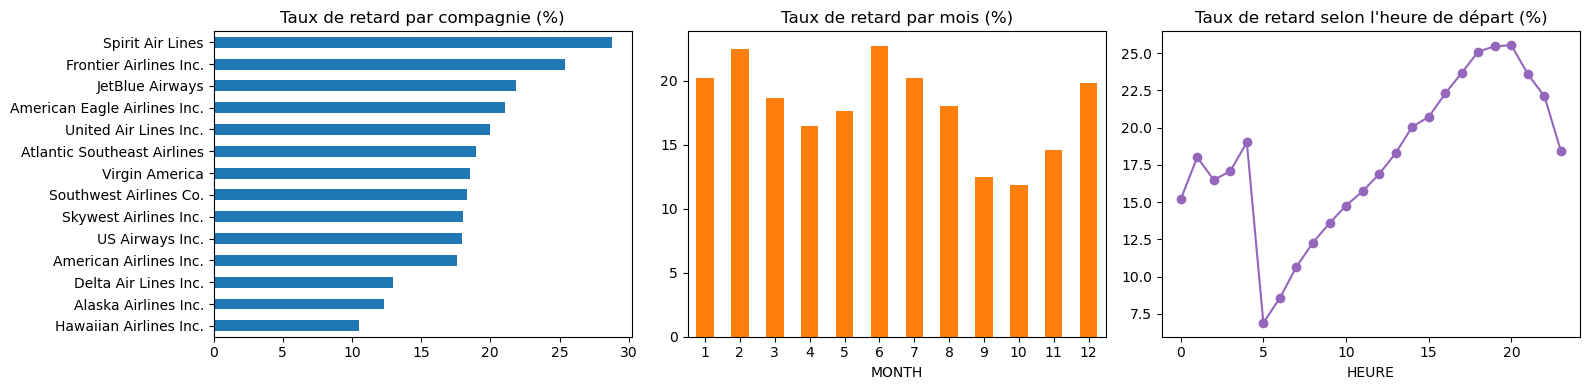

In [8]:
import os
print("Vols annulés :", round(vols["CANCELLED"].mean() * 100, 1), "%")

arrives = vols.dropna(subset=["ARRIVAL_DELAY"]).copy()
arrives["RETARD"] = (arrives["ARRIVAL_DELAY"] > 15).astype(int)
arrives["HEURE"] = arrives["SCHEDULED_DEPARTURE"] // 100
print("Vols en retard (> 15 min) :", round(arrives["RETARD"].mean() * 100, 1), "%")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

par_compagnie = arrives.groupby("AIRLINE")["RETARD"].mean().sort_values() * 100
par_compagnie.index = par_compagnie.index.map(compagnies.set_index("IATA_CODE")["AIRLINE"])
par_compagnie.plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Taux de retard par compagnie (%)")
axes[0].set_ylabel("")

(arrives.groupby("MONTH")["RETARD"].mean() * 100).plot.bar(ax=axes[1], color="tab:orange", rot=0)
axes[1].set_title("Taux de retard par mois (%)")

(arrives.groupby("HEURE")["RETARD"].mean() * 100).plot(ax=axes[2], marker="o", color="tab:purple")
axes[2].set_title("Taux de retard selon l'heure de départ (%)")

plt.tight_layout()
plt.show()

## 3. Prétraitement

- On retire les vols **annulés** ou **déroutés** : ils n'ont pas de retard à l'arrivée.
- On retire les lignes avec des valeurs manquantes.

In [9]:
print("Lignes au départ :", len(vols))
vols = vols[(vols["CANCELLED"] == 0) & (vols["DIVERTED"] == 0)]
vols = vols.dropna()
print("Lignes après nettoyage :", len(vols))

Lignes au départ : 5819079
Lignes après nettoyage : 5714008


## 4. Transformation

- **Cible :** RETARD = 1 si le vol arrive avec plus de 15 minutes de retard.
- **Variables :** mois, jour de la semaine, heure de départ prévue, distance, durée prévue et compagnie.
- On n'utilise **pas** le retard au départ : on ne le connaît qu'au moment du décollage, ce serait une **fuite d'information**.
- La compagnie est du texte : get_dummies la transforme en colonnes 0/1.
- Pour aller vite, on travaille sur un **échantillon de 300 000 vols**.

In [10]:
vols = vols.sample(300_000, random_state=42)
vols["RETARD"] = (vols["ARRIVAL_DELAY"] > 15).astype(int)
vols["HEURE"] = vols["SCHEDULED_DEPARTURE"] // 100

X = pd.get_dummies(vols[["MONTH", "DAY_OF_WEEK", "HEURE", "DISTANCE", "SCHEDULED_TIME", "AIRLINE"]],
                   columns=["AIRLINE"], dtype=int)
y = vols["RETARD"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Entraînement :", len(X_train), "| Test :", len(X_test))
X.head()

Entraînement : 240000 | Test : 60000


,MONTH,DAY_OF_WEEK,HEURE,DISTANCE,SCHEDULED_TIME,AIRLINE_AA,AIRLINE_AS,AIRLINE_B6,AIRLINE_DL,AIRLINE_EV,AIRLINE_F9,AIRLINE_HA,AIRLINE_MQ,AIRLINE_NK,AIRLINE_OO,AIRLINE_UA,AIRLINE_US,AIRLINE_VX,AIRLINE_WN
3335058,7,1,16,318,75.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4857110,10,5,18,950,165.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4454180,10,1,11,672,115.0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
5132772,11,2,13,214,62.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4075015,9,5,6,224,60.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


## 5. ML

Deux modèles simples. class_weight="balanced" compense le faible nombre de vols en retard.

In [11]:
modeles = {
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Arbre de décision": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42),
}
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
print("Modèles entraînés.")

Modèles entraînés.


## 6. Évaluation

Avec des classes déséquilibrées, l'accuracy seule est trompeuse. On regarde surtout le rappel des retards : parmi les vols réellement en retard, combien le modèle en a repéré ?

= Régression logistique
              precision    recall  f1-score   support

   À l'heure       0.87      0.59      0.70     49323
   En retard       0.24      0.60      0.34     10677

    accuracy                           0.59     60000
   macro avg       0.56      0.59      0.52     60000
weighted avg       0.76      0.59      0.64     60000

= Arbre de décision
              precision    recall  f1-score   support

   À l'heure       0.88      0.54      0.67     49323
   En retard       0.24      0.67      0.35     10677

    accuracy                           0.56     60000
   macro avg       0.56      0.61      0.51     60000
weighted avg       0.77      0.56      0.62     60000



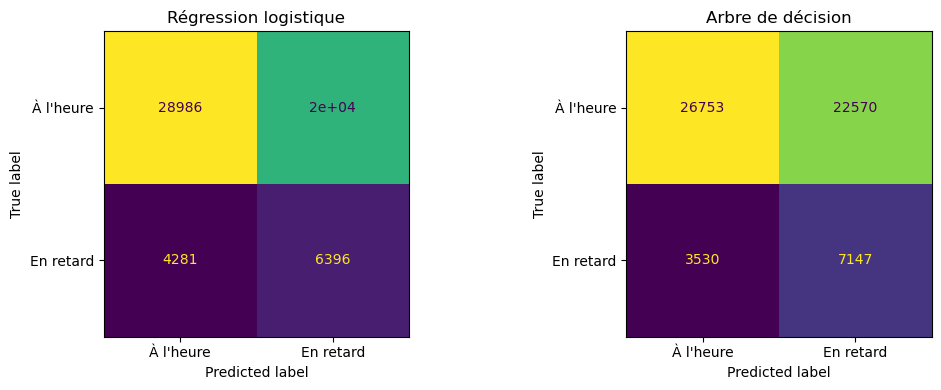

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nom, modele) in zip(axes, modeles.items()):
    print("=", nom)
    print(classification_report(y_test, modele.predict(X_test), target_names=["À l'heure", "En retard"]))
    ConfusionMatrixDisplay.from_estimator(modele, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["À l'heure", "En retard"])
    ax.set_title(nom)
plt.tight_layout()
plt.show()

## 7. Déploiement

On sauvegarde le modèle, puis on l'utilise dans une fonction de prédiction.

In [13]:
joblib.dump(modeles["Arbre de décision"], "modele_vols.joblib")
modele = joblib.load("modele_vols.joblib")


def predire_retard(compagnie, mois, jour_semaine, heure, distance, duree_prevue):
    vol = pd.DataFrame(0, index=[0], columns=X.columns)
    vol[["MONTH", "DAY_OF_WEEK", "HEURE", "DISTANCE", "SCHEDULED_TIME"]] = [mois, jour_semaine, heure, distance, duree_prevue]
    vol["AIRLINE_" + compagnie] = 1
    proba = modele.predict_proba(vol)[0, 1]
    return f"Probabilité de retard : {proba:.0%}"



print("Départ à 7h  :", predire_retard("AA", mois=7, jour_semaine=5, heure=7, distance=2475, duree_prevue=360))
print("Départ à 19h :", predire_retard("AA", mois=7, jour_semaine=5, heure=19, distance=2475, duree_prevue=360))

Départ à 7h  : Probabilité de retard : 37%
Départ à 19h : Probabilité de retard : 63%


## Conclusion

Les 7 étapes ont été réalisées avec pandas et scikit-learn sur une seule machine, mais l'entraînement n'a utilisé qu'un **échantillon de 300 000 vols sur 5,8 millions**. L'étape 2 refera le même travail avec **Spark** pour utiliser toutes les données.